# 03b — APTOS Fine-Tuning (Stage 2)

Fine-tune the EyePACS pre-trained EfficientNetV2-S on the APTOS 2019 dataset.

**Why two stages?**
- EyePACS has ~35K images but noisy labels → learns robust retinal features
- APTOS has ~3.6K images with clean clinical labels → calibrates grade boundaries

**Strategy:**
- Load best Stage 1 checkpoint (`best_model_s1_phase3.pth`)
- Full backbone unfreeze with very low LR (1e-5 backbone, 1e-4 head)
- EMA for stable weight averaging
- Evaluate on APTOS test set
- Training uses the same **AMP dtype** as Stage 1 (`config.AMP_DTYPE` / `Trainer`).

After training, this notebook merges checkpoint info into `outputs/logs/run_manifest.json`.


In [1]:
import importlib
import os
import sys

IS_COLAB = "google.colab" in str(get_ipython()) if "get_ipython" in dir() else False

if IS_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = "/content/drive/MyDrive/diabetic_retinopathy"
    %pip install -q timm albumentations kaggle scipy
else:
    PROJECT_ROOT = os.path.abspath("..")

if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import src.config
importlib.reload(src.config)
from src import config
config.ensure_dirs()


In [2]:
import pandas as pd
import torch

from src.augmentations import get_train_transforms, get_valid_transforms
from src.data_manager import ensure_aptos_dataset
from src.dataset import (
    compute_class_weights,
    create_dataloaders,
    load_and_split_dataframe,
    preprocess_images_to_cache,
)
from src.evaluate import compute_metrics, plot_training_curves, predict
from src.model import (
    ModelEMA,
    build_model,
    count_parameters,
    unfreeze_backbone,
)
from src.trainer import Trainer
from src.utils import get_device, log_gpu_memory, seed_everything, write_run_manifest

seed_everything()
device = get_device()
log_gpu_memory("Initial")

write_run_manifest(
    config.RUN_MANIFEST_PATH,
    {"notebook_stage": "03b_aptos_start", "AMP_DTYPE": config.AMP_DTYPE},
    merge=True,
)


Using GPU: NVIDIA H200 (150.1 GB)
Initial | GPU Memory — Allocated: 0.00GB | Reserved: 0.00GB | Total: 150.1GB


## 1. Download & Prepare APTOS Dataset


In [3]:
# Download APTOS if not present (auto-downloads from Kaggle)
ensure_aptos_dataset()

# Load and split
train_df, valid_df, test_df = load_and_split_dataframe(dataset_name="aptos")

print(f"Train : {len(train_df):,} images")
print(f"Valid : {len(valid_df):,} images")
print(f"Test  : {len(test_df):,} images")
print("\nTrain class distribution:")
print(train_df["level"].value_counts().sort_index())


100%|██████████| 9.51G/9.51G [01:03<00:00, 160MB/s] 



Train : 2,563 images
Valid : 549 images
Test  : 550 images

Train class distribution:
level
0    1263
1     259
2     699
3     135
4     207
Name: count, dtype: int64


## 2. Preprocessing Cache + DataLoaders


In [4]:
# Build/verify preprocessed cache
print("Building APTOS preprocessed cache...")
preprocess_images_to_cache(train_df, dataset_name="aptos")
preprocess_images_to_cache(valid_df, dataset_name="aptos")
preprocess_images_to_cache(test_df, dataset_name="aptos")
print("Cache ready.")


Building APTOS preprocessed cache...


2026-05-04 10:49:34 | src.dataset | INFO | Cache build complete: 2563 written, 0 skipped, 0 missing. Cache dir: /teamspace/studios/this_studio/diabetic_retinopathy/dataset_aptos/preprocessed_512_aptos
2026-05-04 10:49:34 | src.dataset | INFO | Cache metadata mismatch detected in /teamspace/studios/this_studio/diabetic_retinopathy/dataset_aptos/preprocessed_512_aptos; forcing refresh.
2026-05-04 10:50:28 | src.dataset | INFO | Cache build complete: 549 written, 0 skipped, 0 missing. Cache dir: /teamspace/studios/this_studio/diabetic_retinopathy/dataset_aptos/preprocessed_512_aptos
2026-05-04 10:50:28 | src.dataset | INFO | Cache metadata mismatch detected in /teamspace/studios/this_studio/diabetic_retinopathy/dataset_aptos/preprocessed_512_aptos; forcing refresh.
2026-05-04 10:51:22 | src.dataset | INFO | Cache build complete: 550 written, 0 skipped, 0 missing. Cache dir: /teamspace/studios/this_studio/diabetic_retinopathy/dataset_aptos/preprocessed_512_aptos


Cache ready.


In [5]:
# Create dataloaders
train_tfm = get_train_transforms(config.STAGE2_IMG_SIZE)
valid_tfm = get_valid_transforms(config.STAGE2_IMG_SIZE)

loaders = create_dataloaders(
    train_df=train_df,
    valid_df=valid_df,
    dataset_name="aptos",
    test_df=test_df,
    train_transform=train_tfm,
    valid_transform=valid_tfm,
    batch_size=config.STAGE2_BATCH_SIZE,
)

# Class weights
class_weights = compute_class_weights(train_df["level"].values)
print("Class weights:")
for name, w in zip(config.CLASS_NAMES, class_weights, strict=True):
    print(f"  {name:20s}: {w:.4f}")

print(f"\nTrain batches: {len(loaders['train'])}")
print(f"Valid batches: {len(loaders['valid'])}")
print(f"Test batches:  {len(loaders['test'])}")


2026-05-04 10:51:22 | src.dataset | INFO | Using preprocessed cache: /teamspace/studios/this_studio/diabetic_retinopathy/dataset_aptos/preprocessed_512_aptos
2026-05-04 10:51:22 | src.dataset | INFO | Using preprocessed cache: /teamspace/studios/this_studio/diabetic_retinopathy/dataset_aptos/preprocessed_512_aptos
2026-05-04 10:51:22 | src.dataset | INFO | Using preprocessed cache: /teamspace/studios/this_studio/diabetic_retinopathy/dataset_aptos/preprocessed_512_aptos


Class weights:
  No_DR               : 0.4059
  Mild                : 1.9792
  Moderate            : 0.7333
  Severe              : 3.7970
  Proliferative_DR    : 2.4763

Train batches: 20
Valid batches: 5
Test batches:  5


## 3. Load Stage 1 Checkpoint


In [6]:
# Build model and load pretrained Stage 1 weights
model = build_model(pretrained=False)

s1_ckpt = os.path.join(config.CHECKPOINTS_DIR, "best_model_s1_phase3.pth")
if os.path.isfile(s1_ckpt):
    ckpt = torch.load(s1_ckpt, map_location=device, weights_only=False)
    model.load_state_dict(ckpt["model_state_dict"])
    print(f"Loaded Stage 1 checkpoint: {s1_ckpt}")
    print(f"  Stage 1 QWK: {ckpt.get('qwk', 'N/A')}")
else:
    print(f"WARNING: Stage 1 checkpoint not found at {s1_ckpt}")
    print("Using ImageNet pretrained weights instead.")
    model = build_model(pretrained=True)

# Full unfreeze for fine-tuning
unfreeze_backbone(model, from_block=None)
print(f"\nParameters: {count_parameters(model)}")

model = model.to(device)


Loaded Stage 1 checkpoint: /teamspace/studios/this_studio/diabetic_retinopathy/outputs/checkpoints/best_model_s1_phase3.pth
  Stage 1 QWK: N/A

Parameters: {'total': 21169238, 'trainable': 21015366, 'frozen': 153872, 'trainable_pct': 99.27313396920569}


## 4. Fine-Tune on APTOS

| Setting | Value |
|---------|-------|
| LR (backbone) | 1e-5 |
| LR (head) | 1e-4 (10x) |
| Weight decay | 5e-4 |
| Epochs | 20 |
| Mixup | Yes |
| EMA | Yes |


In [8]:
# EMA + Trainer
ema = ModelEMA(model) if config.USE_EMA else None

trainer = Trainer(
    model=model,
    device=device,
    class_weights=class_weights,
    ema=ema,
)

log_gpu_memory("After model init")

# Fine-tune
trainer.fit_phase(
    phase="aptos_finetune",
    train_loader=loaders["train"],
    valid_loader=loaders["valid"],
    epochs=config.STAGE2_EPOCHS,
    lr=config.STAGE2_LR * (config.STAGE2_BATCH_SIZE / 256.0),
    weight_decay=config.STAGE2_WEIGHT_DECAY,
    warmup_epochs=config.STAGE2_WARMUP_EPOCHS,
    use_mixup=False,
    use_amp=True,
)

2026-05-04 10:53:24 | src.trainer | INFO | AMP dtype=torch.bfloat16 grad_scaler=False
2026-05-04 10:53:24 | src.trainer | INFO | 
2026-05-04 10:53:24 | src.trainer | INFO | Phase: APTOS_FINETUNE | Epochs: 25 | LR: 1.5e-05 | Mixup: False | AMP: True (dtype=torch.bfloat16, scaler=False)
2026-05-04 10:53:24 | src.trainer | INFO | ============================================================


After model init | GPU Memory — Allocated: 18.27GB | Reserved: 18.52GB | Total: 150.1GB


  Train:   0%|          | 0/20 [00:00<?, ?it/s]

OutOfMemoryError: CUDA out of memory. Tried to allocate 384.00 MiB. GPU 0 has a total capacity of 139.80 GiB of which 25.56 MiB is free. Including non-PyTorch memory, this process has 17.86 GiB memory in use. Process 99656 has 121.83 GiB memory in use. Of the allocated memory 17.01 GiB is allocated by PyTorch, and 241.91 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

## 5. Training Curves


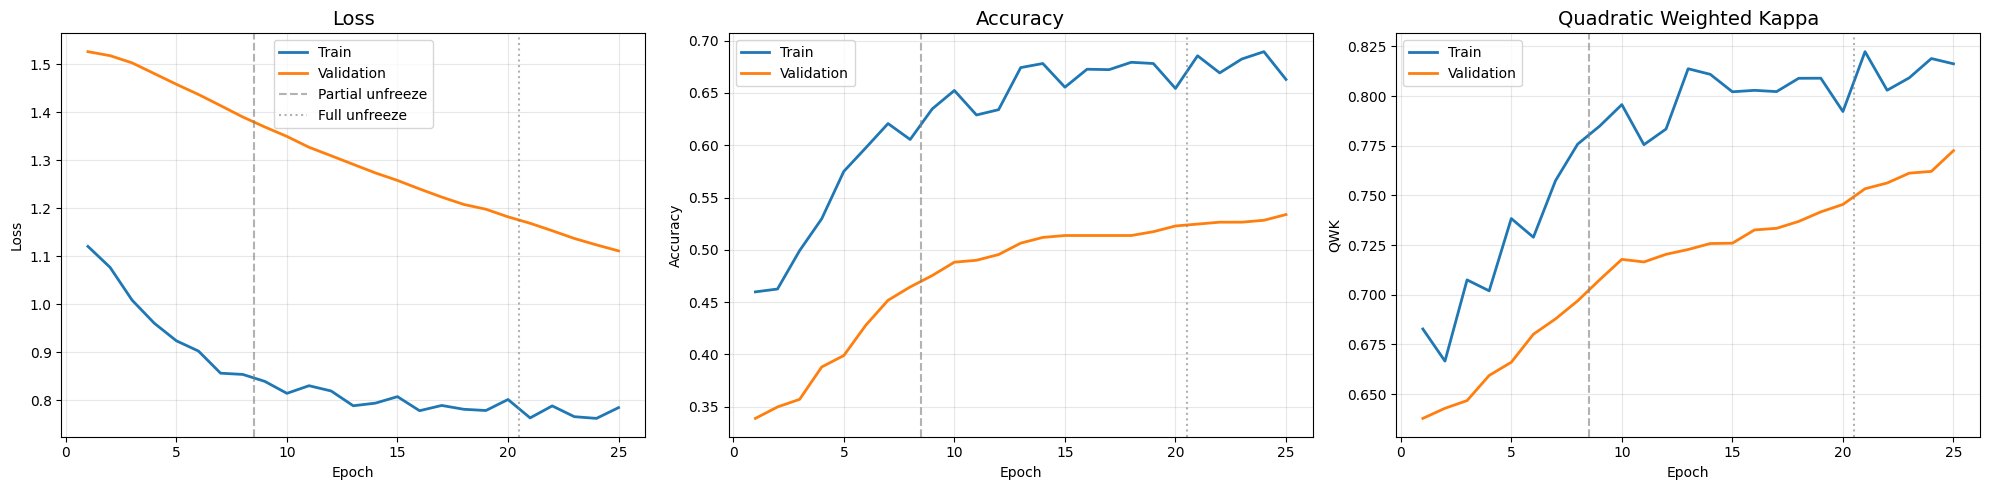

2026-05-01 08:53:10 | src.trainer | INFO | Training history saved to /teamspace/studios/this_studio/diabetic_retinopathy/outputs/logs/stage2_history.json


In [8]:
import os

plot_training_curves(
    trainer.history,
    save_path=os.path.join(config.FIGURES_DIR, "stage2_training_curves.png"),
)
trainer.save_history(os.path.join(config.LOGS_DIR, "stage2_history.json"))

write_run_manifest(
    config.RUN_MANIFEST_PATH,
    {
        "stage_aptos_finetune": True,
        "checkpoint_aptos": os.path.join(config.CHECKPOINTS_DIR, "best_model_aptos_finetune.pth"),
        "STAGE2_BATCH_SIZE": config.STAGE2_BATCH_SIZE,
        "AMP_DTYPE": config.AMP_DTYPE,
    },
    merge=True,
)


## 6. Evaluate on APTOS Test Set


In [9]:
# Load best checkpoint
trainer.load_best_checkpoint("aptos_finetune")

if ema is not None:
    ema.apply(model)
    print("Applied EMA weights for evaluation")

# Predict on test set
y_true, y_pred, y_proba = predict(model, loaders["test"], device)
metrics = compute_metrics(y_true, y_pred, y_proba)

print(f"APTOS Test QWK      : {metrics['qwk']:.4f}")
print(f"APTOS Test Accuracy : {metrics['accuracy']:.4f}")
print(f"APTOS Test ROC-AUC  : {metrics['roc_auc_weighted']:.4f}")
print(f"\n{metrics['classification_report_str']}")


2026-05-01 08:53:16 | src.trainer | INFO | Loaded checkpoint: /teamspace/studios/this_studio/diabetic_retinopathy/outputs/checkpoints/best_model_aptos_finetune.pth (epoch 25, QWK=0.7725)


Applied EMA weights for evaluation


APTOS Test QWK      : 0.7533
APTOS Test Accuracy : 0.5236
APTOS Test ROC-AUC  : 0.8133

                  precision    recall  f1-score   support

           No_DR     0.9873    0.8598    0.9191       271
            Mild     0.2162    0.1429    0.1720        56
        Moderate     0.2333    0.0467    0.0778       150
          Severe     0.0753    0.3793    0.1257        29
Proliferative_DR     0.2871    0.6591    0.4000        44

        accuracy                         0.5236       550
       macro avg     0.3599    0.4175    0.3389       550
    weighted avg     0.5991    0.5236    0.5302       550



## 7. Threshold Optimization

Standard argmax may not be optimal for ordinal classes.
We optimize thresholds on the validation set to maximize QWK.


In [10]:
from scipy.optimize import minimize


def optimize_thresholds(y_true, y_proba, n_classes=5):
    """Find optimal thresholds that maximize QWK on validation set."""
    from sklearn.metrics import cohen_kappa_score

    # Use continuous predictions (expected value)
    y_continuous = (y_proba * torch.arange(n_classes).float()).sum(dim=1).numpy() \
        if isinstance(y_proba, torch.Tensor) else (y_proba * range(n_classes)).sum(axis=1)

    # Initial thresholds at class boundaries
    init_thresholds = [0.5, 1.5, 2.5, 3.5]

    def neg_qwk(thresholds):
        t = sorted(thresholds)
        import numpy as np
        preds = np.digitize(y_continuous, t)
        return -cohen_kappa_score(y_true, preds, weights="quadratic")

    result = minimize(neg_qwk, init_thresholds, method="Nelder-Mead")
    optimal_thresholds = sorted(result.x)

    import numpy as np
    y_pred_opt = np.digitize(y_continuous, optimal_thresholds)
    qwk_opt = cohen_kappa_score(y_true, y_pred_opt, weights="quadratic")

    return optimal_thresholds, qwk_opt, y_pred_opt

# Optimize on validation set
y_true_val, y_pred_val, y_proba_val = predict(model, loaders["valid"], device)
opt_thresholds, qwk_opt, _ = optimize_thresholds(y_true_val, y_proba_val)

# Apply to test set
import numpy as np
y_continuous_test = (y_proba * np.arange(5)).sum(axis=1) if not isinstance(y_proba, torch.Tensor) \
    else (y_proba * torch.arange(5).float()).sum(dim=1).numpy()
y_pred_opt_test = np.digitize(y_continuous_test, opt_thresholds)

from sklearn.metrics import cohen_kappa_score
qwk_argmax = cohen_kappa_score(y_true, y_pred, weights="quadratic")
qwk_threshold = cohen_kappa_score(y_true, y_pred_opt_test, weights="quadratic")

print(f"Optimal thresholds: {[f'{t:.3f}' for t in opt_thresholds]}")
print(f"\nTest QWK (argmax):              {qwk_argmax:.4f}")
print(f"Test QWK (optimized thresholds): {qwk_threshold:.4f}")
print(f"Improvement:                     {qwk_threshold - qwk_argmax:+.4f}")


Optimal thresholds: ['0.811', '1.225', '2.570', '3.547']

Test QWK (argmax):              0.7533
Test QWK (optimized thresholds): 0.7714
Improvement:                     +0.0181


## 8. ONNX Export


In [11]:
from src.export import export_to_onnx

onnx_path = export_to_onnx(
    checkpoint_path=os.path.join(config.CHECKPOINTS_DIR, "best_model_aptos_finetune.pth"), opset_version=18
)
print(f"\nONNX model exported to: {onnx_path}")


2026-05-01 08:53:28 | src.export | INFO | Loaded checkpoint: /teamspace/studios/this_studio/diabetic_retinopathy/outputs/checkpoints/best_model_aptos_finetune.pth (epoch 24, QWK=0.7725472551264517)
/teamspace/studios/this_studio/diabetic_retinopathy/src/export.py:75: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(


[torch.onnx] Obtain model graph for `DRModel([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `DRModel([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


/system/conda/miniconda3/uv/python/cpython-3.12.11-linux-x86_64-gnu/lib/python3.12/copyreg.py:99: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅


2026-05-01 08:53:37 | src.export | INFO | ONNX validation passed (max diff: 4.17e-07)
2026-05-01 08:53:37 | src.export | INFO | ONNX model exported: /teamspace/studios/this_studio/diabetic_retinopathy/outputs/checkpoints/model.onnx (81.8 MB, opset 18)



ONNX model exported to: /teamspace/studios/this_studio/diabetic_retinopathy/outputs/checkpoints/model.onnx


## 9. Save Test Split

Save for use in `04_evaluation.ipynb`.


In [12]:
test_csv_path = os.path.join(config.OUTPUTS_DIR, "test_split_aptos.csv")
test_df.to_csv(test_csv_path, index=False)
print(f"APTOS test split saved: {test_csv_path} ({len(test_df)} images)")


APTOS test split saved: /teamspace/studios/this_studio/diabetic_retinopathy/outputs/test_split_aptos.csv (550 images)
